# Лабораторная работа 3. Кластеризация аудиопризнаков треков Spotify

## 1. Введение

Цель работы: изучение алгоритмов кластеризации, приобретение навыков оценки качества разбиения данных на кластеры и интерпретации результатов.

Постановка задачи:

1. Загрузить датасет для задачи кластеризации / классификации (например, с платформы Kaggle). Провести дескриптивный анализ данных: определить размерность, типы признаков, наличие пропусков. Оценить распределение переменных (близость к нормальному) с использованием визуализации (гистограммы). Оценить информационную значимость признаков. Проверить условие применения кластеризации: отсутствие классов, осмысленность кластеризации, отсутствие выбросов.
2. Выполнить стандартизацию / нормализацию числовых признаков. Обосновать выбор метода масштабирования. Построить матрицу диаграмм рассеивания для визуальной оценки структуры данных, предположительного количества кластеров и типа кластерной структуры. Аргументировать выбор методов кластеризации на основе формы, размера и плотности кластеров.
3. Реализовать кластеризацию двумя различными методами на выбор: K-means (K-средних); иерархическая кластеризация; DBSCAN; EM-алгоритм (Gaussian Mixture). Для методов, требующих задания числа кластеров (K-means, иерархическая), подобрать оптимальное значение k с использованием: метода локтя и / или анализа силуэта.
4. Рассчитать метрики качества для обоих методов: внутренние и внешние. Оценить расстояние между кластерами, внутрикластерные расстояния, компактность кластеров, центры кластеров. Опционально, если известно разделение на классы, посчитать: индекс Rand, индекс Жаккара и др. внешние метрики. Привести содержательную интерпретацию полученных значений.
5. Исследовать влияние параметров одного из методов (например, ε и min_samples для DBSCAN или количества кластеров k для K-means) на качество кластеризации.
6. Визуализировать полученные кластеры в пространстве признаков (использовать PCA для снижения размерности при необходимости). Проанализировать центры кластеров и дать содержательную интерпретацию выделенных групп. Сравнить результаты, полученные двумя разными методами.

Жанровой метки у трека в этом файле нет, поэтому качество оценивается внутренними метриками. Индексы Rand и Жаккара относительно истинных классов не определены: сравнивать разбиение не с чем. Согласованность двух методов измеряется adjusted Rand index и нормализованной взаимной информацией.


## 2. Описание датасета

Источник: Yamac Eren Ay, Spotify Dataset 1921–2020, 160k+ Tracks (Kaggle, данные Spotify Web API). В работе используется файл `data.csv`: одна строка — один трек. Файлы `data_by_artist`, `data_by_genres`, `data_by_year` и `data_w_genres` содержат уже усреднённые объекты, поэтому для кластеризации треков они не берутся.

Аудиопризнаки, по которым считается расстояние:

| Признак | Содержание | Типичный диапазон |
|---|---|---|
| acousticness | насколько запись акустическая | 0–1 |
| danceability | танцевальность | 0–1 |
| energy | энергия | 0–1 |
| instrumentalness | доля инструментального звучания, без голоса | 0–1 |
| liveness | вероятность живого исполнения | 0–1 |
| loudness | громкость | дБ, примерно от −60 до 0 |
| speechiness | доля речи | 0–1 |
| tempo | темп | удары в минуту |
| valence | позитивная окраска | 0–1 |
| duration_ms | длительность | миллисекунды |

В расстояние не входят:

- `id`, `name`, `artists`, `release_date` — идентификаторы и текст;
- `year` и `popularity` — год и коммерческий успех, а не тембр; они нужны только при интерпретации уже полученных групп;
- `key` — тональность закодирована числами 0–11. Это циклическая номинальная шкала: до и си соседние звуки, а их коды 0 и 11 далеки в евклидовой метрике;
- `mode` и `explicit` — бинарные флаги лада и ненормативной лексики.


In [1]:
%matplotlib inline

import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    normalized_mutual_info_score,
    silhouette_samples,
    silhouette_score,
)
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 12,
    "font.family": "DejaVu Sans",
    "savefig.facecolor": "white",
})

try:
    HERE = Path(__file__).resolve().parent
except NameError:
    HERE = Path.cwd()
FIGURES = HERE / "figures"
RESULTS = HERE / "results"
FIGURES.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)


def save_show(name):
    plt.gcf().savefig(FIGURES / name, bbox_inches="tight")
    print("Сохранён график:", name)
    plt.show()


def save_table(frame, name):
    frame.to_csv(RESULTS / name, encoding="utf-8-sig")
    print("Сохранена таблица:", name)

RANDOM_STATE = 42
SAMPLE_SIZE = 6000
K_RANGE = range(2, 11)
AUDIO_FEATURES = [
    "acousticness",
    "danceability",
    "energy",
    "instrumentalness",
    "liveness",
    "loudness",
    "speechiness",
    "tempo",
    "valence",
    "duration_ms",
]
CLUSTER_ORDER = ["Акустические", "Энергичные", "Речевые"]
PALETTE = {
    "Акустические": "#4C78A8",
    "Энергичные": "#F58518",
    "Речевые": "#54A24B",
}

tracks = pd.read_csv("data.csv")
print(f"Размерность: {tracks.shape[0]} строк, {tracks.shape[1]} столбцов")
print(f"Дубликаты id: {int(tracks['id'].duplicated().sum())}")
print(f"Пропуски: {int(tracks.isna().sum().sum())}")
display(tracks.dtypes.rename("тип").to_frame())


Размерность: 170653 строк, 19 столбцов
Дубликаты id: 0
Пропуски: 0


,тип
valence,float64
year,int64
acousticness,float64
artists,str
danceability,float64
duration_ms,int64
energy,float64
explicit,int64
id,str
instrumentalness,float64


В файле 170 653 трека и 19 столбцов. Пропусков нет, идентификаторы не повторяются. Числовые поля имеют тип `int64` или `float64`, названия и исполнители — строки. Годы выпуска занимают интервал 1921–2020.


In [2]:
summary = tracks[AUDIO_FEATURES].describe().T
summary["skew"] = tracks[AUDIO_FEATURES].skew()
summary["excess_kurtosis"] = tracks[AUDIO_FEATURES].kurtosis()
summary = summary.rename(columns={
    "count": "n",
    "mean": "среднее",
    "std": "СКО",
    "min": "мин",
    "25%": "Q1",
    "50%": "медиана",
    "75%": "Q3",
    "max": "макс",
    "skew": "асимметрия",
    "excess_kurtosis": "эксцесс",
})
display(summary.round(3))
save_table(summary.round(3), "описательные_статистики.csv")


,n,среднее,СКО,мин,Q1,медиана,Q3,макс,асимметрия,эксцесс
acousticness,170653.0,0.502,0.376,0.0,0.102,0.516,0.893,0.996,-0.033,-1.609
danceability,170653.0,0.537,0.176,0.0,0.415,0.548,0.668,0.988,-0.223,-0.443
energy,170653.0,0.482,0.268,0.0,0.255,0.471,0.703,1.000,0.112,-1.100
instrumentalness,170653.0,0.167,0.313,0.0,0.000,0.000,0.102,1.000,1.631,0.942
liveness,170653.0,0.206,0.175,0.0,0.099,0.136,0.261,1.000,2.154,5.001
loudness,170653.0,-11.468,5.698,-60.0,-14.615,-10.580,-7.183,3.855,-1.052,1.847
speechiness,170653.0,0.098,0.163,0.0,0.035,0.045,0.076,0.970,4.048,17.000
tempo,170653.0,116.862,30.709,0.0,93.421,114.729,135.537,243.507,0.450,-0.078
valence,170653.0,0.529,0.263,0.0,0.317,0.540,0.747,1.000,-0.107,-1.062
duration_ms,170653.0,230948.311,126118.415,5108.0,169827.000,207467.000,262400.000,5403500.000,7.314,132.922


Сохранена таблица: описательные_статистики.csv


Сохранена таблица:

 нормальность.csv


признак,"асимметрия, n=170653","эксцесс, n=170653","Шапиро–Уилк W, n=5000","p-value, n=5000"
acousticness,-0.033,-1.609,0.863,1.02e-54
danceability,-0.223,-0.443,0.991,4.82e-17
energy,0.112,-1.100,0.961,1.35e-34
instrumentalness,1.631,0.942,0.577,1.35e-76
liveness,2.154,5.001,0.748,4.64e-66
loudness,-1.052,1.847,0.936,6.30e-42
speechiness,4.048,17.000,0.442,1.60e-82
tempo,0.450,-0.078,0.981,1.24e-25
valence,-0.107,-1.062,0.967,2.72e-32
duration_ms,7.314,132.922,0.632,1.16e-73


Сохранён график: 01_распределения.png


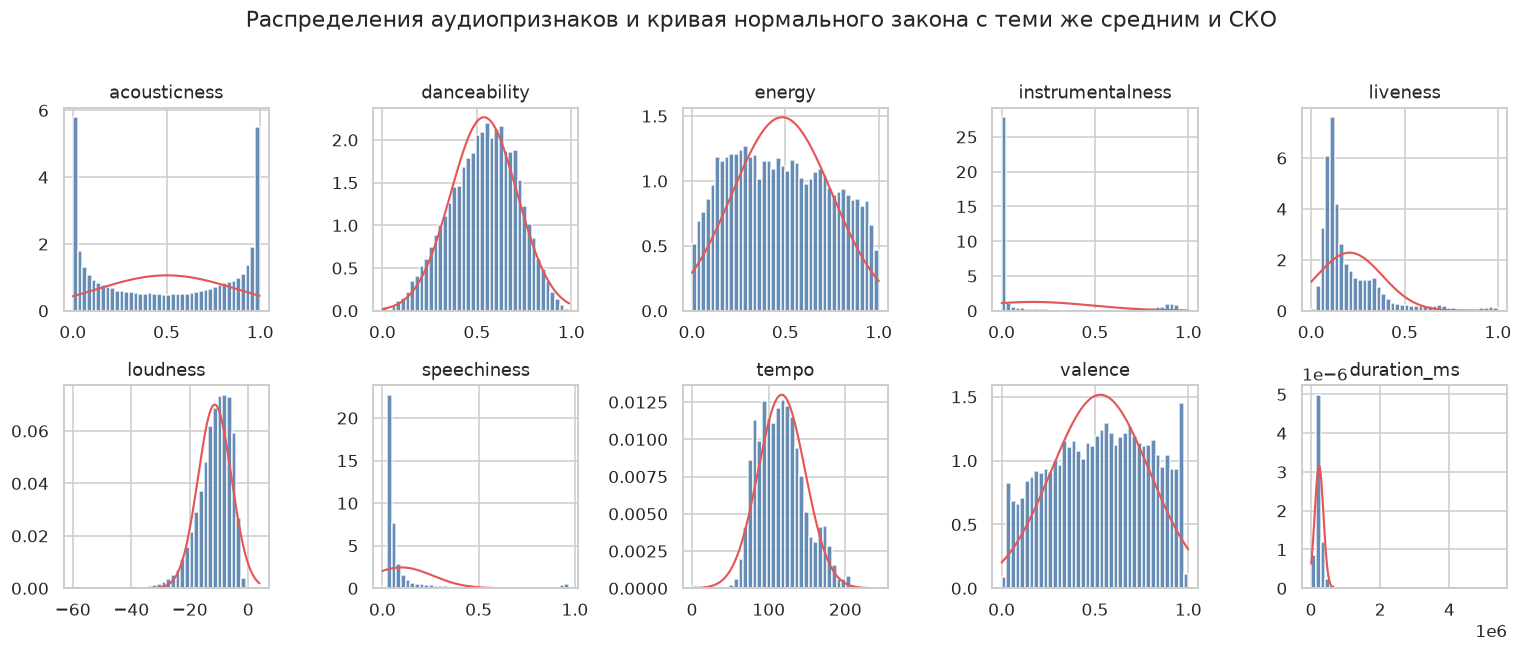

In [3]:
normal_sample = tracks[AUDIO_FEATURES].sample(5000, random_state=RANDOM_STATE)
normality_rows = []
for feature in AUDIO_FEATURES:
    statistic, p_value = stats.shapiro(normal_sample[feature])
    normality_rows.append({
        "признак": feature,
        "асимметрия, n=170653": tracks[feature].skew(),
        "эксцесс, n=170653": tracks[feature].kurtosis(),
        "Шапиро–Уилк W, n=5000": statistic,
        "p-value, n=5000": p_value,
    })
normality = pd.DataFrame(normality_rows)
save_table(normality, "нормальность.csv")
display(normality.style.format({
    "асимметрия, n=170653": "{:.3f}",
    "эксцесс, n=170653": "{:.3f}",
    "Шапиро–Уилк W, n=5000": "{:.3f}",
    "p-value, n=5000": "{:.2e}",
}).hide(axis="index"))

fig, axes = plt.subplots(2, 5, figsize=(14, 5.8))
for axis, feature in zip(axes.ravel(), AUDIO_FEATURES):
    values = tracks[feature].to_numpy()
    axis.hist(values, bins=40, density=True, color="#4C78A8", alpha=0.85, edgecolor="white")
    grid = np.linspace(values.min(), values.max(), 300)
    axis.plot(grid, stats.norm.pdf(grid, values.mean(), values.std(ddof=0)), color="#E45756", lw=1.4)
    axis.set_title(feature)
fig.suptitle("Распределения аудиопризнаков и кривая нормального закона с теми же средним и СКО", y=1.02)
fig.tight_layout()
save_show("01_распределения.png")


Критерий Шапиро–Уилка посчитан на случайной подвыборке 5000 наблюдений: столбцы W и p-value относятся к ней. Асимметрия и эксцесс в той же таблице посчитаны по всем 170 653 строкам. Это разные выборки, их нельзя читать как один расчёт.

W и p-value отвергают нормальность каждого признака: все p-value много меньше 0,05. На 5000 наблюдениях критерий чувствителен к небольшим отклонениям, поэтому форма читается по гистограмме и по асимметрии с эксцессом полной таблицы. Эксцесс здесь избыточный: у нормального закона он равен нулю.

Ближе остальных к симметричному колоколу выглядят danceability (асимметрия около −0,22), valence (около −0,11) и tempo (около 0,45). Даже у них гистограмма площе нормальной кривой. acousticness и energy двумодальны или плосковершинны: масса смещена к краям шкалы, эксцесс около −1,6 и −1,1. instrumentalness, speechiness и liveness имеют острый пик у нуля и длинный правый хвост; асимметрия speechiness около 4,1. loudness скошен влево. duration_ms сильно скошен вправо: асимметрия около 7,3, максимум 5 403 500 мс, около 90 минут. Этот максимум — аудиокнига, а не музыкальный трек.

Для K-means и метода Уорда нормальность признаков не требуется. Приводить хвосты к нормальному виду логарифмом не стоит: как раз крайние значения speechiness и двумодальность acousticness отделяют содержательные группы.


,"доля сырой дисперсии, %, артефакт единиц"
acousticness,0.000000
danceability,0.000000
energy,0.000000
instrumentalness,0.000000
liveness,0.000000
loudness,0.000000
speechiness,0.000000
tempo,0.000006
valence,0.000000
duration_ms,99.999994


,среднее,СКО,СКО / среднее
acousticness,0.502,0.376,0.749
danceability,0.537,0.176,0.328
energy,0.482,0.268,0.555
instrumentalness,0.167,0.313,1.877
liveness,0.206,0.175,0.849
speechiness,0.098,0.163,1.654
valence,0.529,0.263,0.498


Сохранён график: 02_корреляция.png


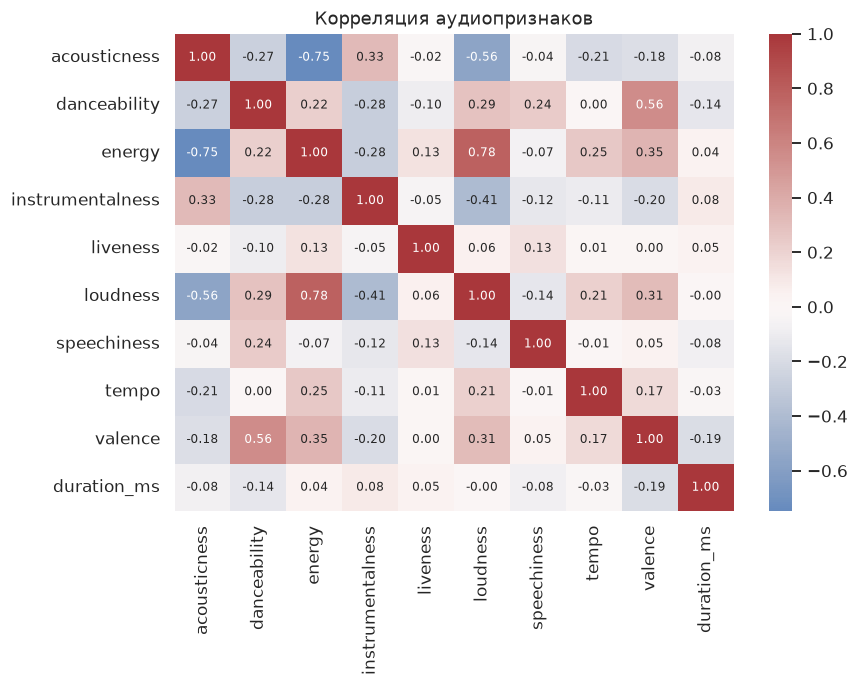

In [4]:
# Не информационная значимость: дисперсия duration_ms считается в мс²,
# поэтому доля сырой дисперсии — артефакт единиц измерения.
raw_variance_share = tracks[AUDIO_FEATURES].var()
raw_variance_share = (raw_variance_share / raw_variance_share.sum() * 100).rename(
    "доля сырой дисперсии, %, артефакт единиц"
)
display(raw_variance_share.to_frame().style.format("{:.6f}"))

bounded = ["acousticness", "danceability", "energy", "instrumentalness", "liveness", "speechiness", "valence"]
spread = tracks[bounded].agg(["mean", "std"]).T
spread["СКО / среднее"] = spread["std"] / spread["mean"]
spread = spread.rename(columns={"mean": "среднее", "std": "СКО"})
display(spread.round(3))

correlation = tracks[AUDIO_FEATURES].corr()
fig, axis = plt.subplots(figsize=(8.2, 6.4))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="vlag", center=0, ax=axis, annot_kws={"size": 8})
axis.set_title("Корреляция аудиопризнаков")
fig.tight_layout()
save_show("02_корреляция.png")


Величина `raw_variance_share` — не информационная значимость признаков. Это доля сырой дисперсии до масштабирования, и она является артефактом единиц измерения. Дисперсия `duration_ms` считается в мс². Длительность имеет порядок 10⁵ мс, поэтому её дисперсия на много порядков больше дисперсии признаков на шкале 0–1, в децибелах или в ударах в минуту. В таблице на `duration_ms` приходится 99,999994% (при округлении до четырёх знаков это 99,9999%; при меньшем числе знаков доля выглядит как 100%) сырой дисперсии. Это не значит, что длительность содержательно важнее остальных признаков: в евклидовом расстоянии она просто задавит их, пока шкалы не уравнены. Отсюда необходимость стандартизации.

Информационную значимость оценивают уже сравнимые величины. На общей шкале 0–1 самый большой разброс у acousticness (СКО около 0,38) и instrumentalness (около 0,31). speechiness имеет меньшее СКО, но тяжёлый хвост: редкие почти полностью речевые записи в среднем квадратичном теряются. Корреляции собираются в два содержательных пучка. energy, loudness и acousticness связаны сильно: energy и loudness около 0,78, energy и acousticness около −0,75. Это одна ось «тихое акустическое — громкое энергичное». danceability и valence коррелируют примерно на 0,55. liveness, tempo и duration_ms с остальными признаками почти не связаны, модуль корреляции не превышает 0,25, поэтому это отдельные оси, а не дубли уже учтённого контраста.


Сохранена таблица: выбросы_iqr.csv


,Q1,Q3,нижняя граница,верхняя граница,"за границей, шт.","за границей, доля"
acousticness,0.102,0.893,-1.085,2.080,0,0.0%
danceability,0.415,0.668,0.036,1.047,143,0.1%
energy,0.255,0.703,-0.417,1.375,0,0.0%
instrumentalness,0.000,0.102,-0.153,0.255,36105,21.2%
liveness,0.099,0.261,-0.145,0.504,11808,6.9%
loudness,-14.615,-7.183,-25.763,3.965,3501,2.1%
speechiness,0.035,0.076,-0.026,0.137,23937,14.0%
tempo,93.421,135.537,30.247,198.711,1645,1.0%
valence,0.317,0.747,-0.328,1.392,0,0.0%
duration_ms,169827.000,262400.000,30967.500,401259.500,9518,5.6%


Сохранён график: 03_ящики_с_усами.png


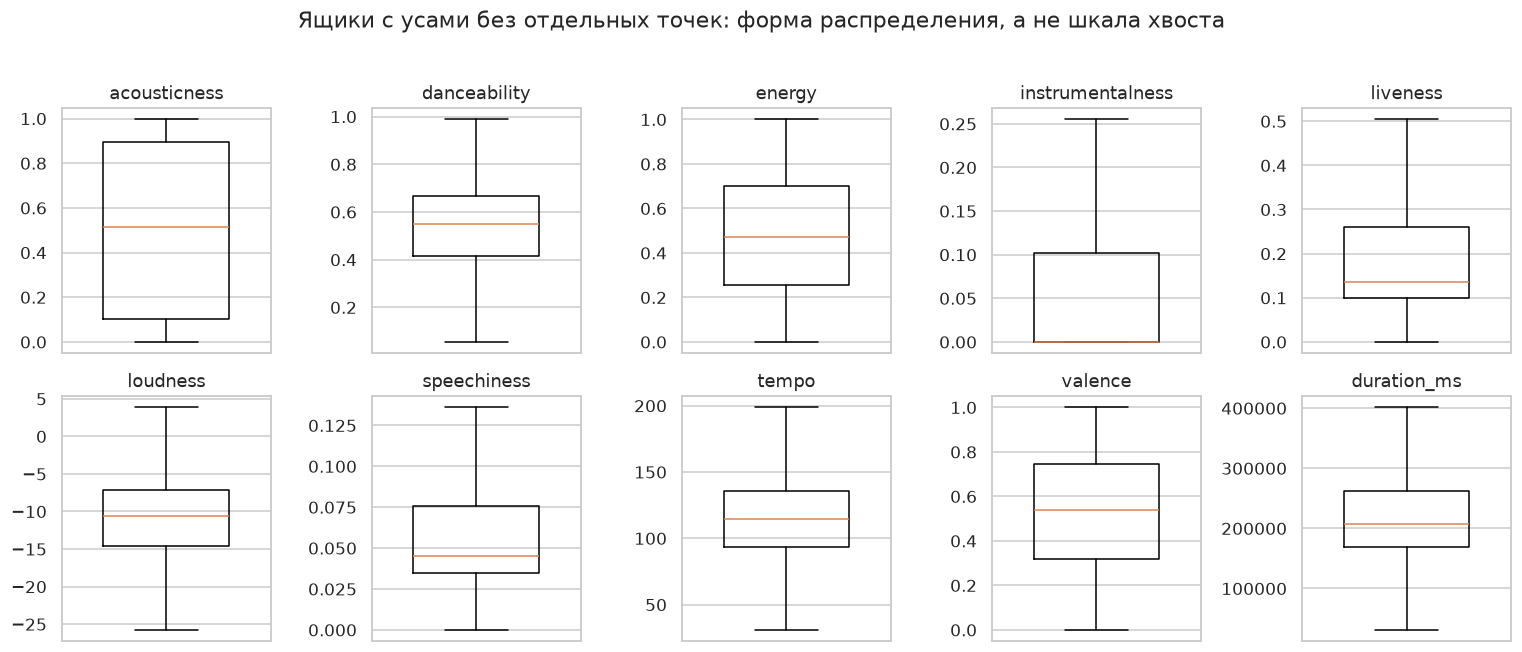

duration_ms: медиана 207467 мс, максимум 5403500 мс (около 90 минут — аудиокнига, не трек); tempo = 0 у 143 строк, danceability = 0 у 143 строк (дефект Spotify API, не пустые треки).


In [5]:
def iqr_fence_share(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    outside = (series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)
    return pd.Series({
        "Q1": q1,
        "Q3": q3,
        "нижняя граница": q1 - 1.5 * iqr,
        "верхняя граница": q3 + 1.5 * iqr,
        "за границей, шт.": int(outside.sum()),
        "за границей, доля": outside.mean(),
    })

iqr_table = tracks[AUDIO_FEATURES].apply(iqr_fence_share).T
save_table(iqr_table, "выбросы_iqr.csv")
display(iqr_table.style.format({
    "Q1": "{:.3f}",
    "Q3": "{:.3f}",
    "нижняя граница": "{:.3f}",
    "верхняя граница": "{:.3f}",
    "за границей, шт.": "{:.0f}",
    "за границей, доля": "{:.1%}",
}))

fig, axes = plt.subplots(2, 5, figsize=(14, 5.8))
for axis, feature in zip(axes.ravel(), AUDIO_FEATURES):
    axis.boxplot(tracks[feature], showfliers=False, widths=0.6)
    axis.set_title(feature)
    axis.set_xticks([])
fig.suptitle("Ящики с усами без отдельных точек: форма распределения, а не шкала хвоста", y=1.02)
fig.tight_layout()
save_show("03_ящики_с_усами.png")

print(
    "duration_ms: медиана "
    f"{tracks['duration_ms'].median():.0f} мс, максимум {tracks['duration_ms'].max():.0f} мс "
    "(около 90 минут — аудиокнига, не трек); "
    f"tempo = 0 у {(tracks['tempo'] <= 0).sum()} строк, "
    f"danceability = 0 у {(tracks['danceability'] <= 0).sum()} строк "
    "(дефект Spotify API, не пустые треки)."
)


Формальное правило полутора межквартильных размахов помечает 21% значений instrumentalness, 14% speechiness, 7% liveness и 6% duration_ms. Для instrumentalness и speechiness это не ошибки измерения. У обоих распределений узкий межквартильный размах рядом с нулём, поэтому вся правая часть, где лежат инструментальные и речевые записи, оказывается «за границей». Удаление этих точек уничтожило бы как раз те группы, которые кластеризация должна уметь увидеть. Точки на ящиках с усами скрыты только для читаемости: иначе аудиокнига длительностью около 90 минут сжимает ящик duration_ms в линию. Это не трек. Число таких объектов показано в таблице.

Условие применимости кластеризации выполняется с одной оговоркой по выбросам.

1. Класса нет. В `data.csv` нет жанра и другой метки, которую требовалось бы восстановить. `key`, `mode` и `explicit` являются свойствами записи, а не размеченным целевым классом.
2. Группировка осмысленна. Признаки описывают слышимый характер трека, а сильные корреляции показывают, что объекты уже лежат вдоль нескольких музыкальных осей, а не образуют сферический шум.
3. Грубые ошибки есть, содержательные хвосты тоже. `tempo = 0` и `danceability = 0` у одних и тех же 143 строк — дефект Spotify API, а не пустые треки. Максимум `duration_ms` около 90 минут — аудиокнига, а не трек. Хвосты speechiness, instrumentalness и liveness остаются в данных: это форма распределения, а не ошибка API.


## 3. Предобработка данных

Удаляются только технические дефекты:

- `tempo <= 0` и `danceability = 0` у одних и тех же 143 строк. Это дефект ответа Spotify API, а не пустые или шумовые треки;
- длительность короче 30 секунд или длиннее 10 минут. Нижний порог близок к 0,1%-квантили и отсекает обрывки. Верхний близок к 99%-квантили и убирает объекты вроде аудиокниги длительностью около 90 минут: это не трек, и из-за него длительность в мс² становится отдельным искусственным измерением.

Остальные признаки сохраняются. После очистки строится случайная подвыборка 6000 треков с фиксированным `random_state`. Описательные выводы выше сделаны по всему файлу. Оба алгоритма дальше считаются на одной и той же подвыборке, иначе разбиения нельзя сопоставить. Иерархическая кластеризация Уорда хранит матрицу попарных расстояний. Для 168 тысяч строк это порядка 100 ГБ, для 6000 строк — около 140 МБ. Коэффициент силуэта тоже квадратичен по числу объектов. K-means по полной очищенной таблице считается отдельно, как проверка устойчивости центров.

Масштаб выравнивается `StandardScaler`: из каждого признака вычитается среднее и результат делится на СКО. После преобразования у всех признаков среднее 0 и СКО 1, поэтому евклидово расстояние в K-means и в методе Уорда не зависит от единиц измерения.

MinMaxScaler уравнял бы только минимумы и максимумы. Дисперсии остались бы разными, а новая шкала по-прежнему определялась бы самым крайним значением. RobustScaler опирается на медиану и межквартильный размах и тем самым приглушает хвост speechiness. Этот хвост является отдельной плотной группой, а не помехой, поэтому робастное масштабирование здесь вредно. Стандартизация не требует нормальности и не уничтожает асимметрию: она только выравнивает вклад признаков.


In [6]:
invalid_tempo = tracks["tempo"] <= 0
invalid_duration = ~tracks["duration_ms"].between(30_000, 600_000)
print(f"tempo <= 0: {int(invalid_tempo.sum())}")
print(f"длительность вне [30 с; 10 мин]: {int(invalid_duration.sum())}")
print(f"пересечение этих условий: {int((invalid_tempo & invalid_duration).sum())}")

clean = tracks.loc[~(invalid_tempo | invalid_duration)].copy()
print(f"удалено {len(tracks) - len(clean)} строк ({(len(tracks) - len(clean)) / len(tracks):.1%})")
print(f"осталось {len(clean)} строк")

sample = clean.sample(SAMPLE_SIZE, random_state=RANDOM_STATE).reset_index(drop=True)
comparison = pd.DataFrame({
    "вся очищенная таблица": clean[AUDIO_FEATURES].mean(),
    "подвыборка 6000": sample[AUDIO_FEATURES].mean(),
})
comparison["относительное отклонение"] = (
    comparison["подвыборка 6000"] - comparison["вся очищенная таблица"]
) / comparison["вся очищенная таблица"]
display(comparison.round(4))
save_table(comparison.round(4), "подвыборка_средние.csv")

scaler = StandardScaler()
X = scaler.fit_transform(sample[AUDIO_FEATURES])
scaled = pd.DataFrame(X, columns=AUDIO_FEATURES)
print("Средние после StandardScaler:", np.round(scaled.mean().to_numpy(), 8))
print("СКО после StandardScaler:", np.round(scaled.std(ddof=0).to_numpy(), 8))


tempo <= 0: 143
длительность вне [30 с; 10 мин]: 2442
пересечение этих условий: 21
удалено 2564 строк (1.5%)
осталось 168089 строк


,вся очищенная таблица,подвыборка 6000,относительное отклонение
acousticness,0.4992,0.5006,0.0030
danceability,0.5403,0.5394,-0.0017
energy,0.4849,0.4824,-0.0050
instrumentalness,0.1628,0.1623,-0.0030
liveness,0.2049,0.2058,0.0045
loudness,-11.3940,-11.3914,-0.0002
speechiness,0.0982,0.0984,0.0025
tempo,117.1023,116.8088,-0.0025
valence,0.5324,0.5284,-0.0074
duration_ms,222131.2918,222538.4000,0.0018


Сохранена таблица: подвыборка_средние.csv
Средние после StandardScaler: [ 0. -0. -0.  0. -0. -0.  0. -0. -0.  0.]
СКО после StandardScaler: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


Средние подвыборки отличаются от средних всей очищенной таблицы меньше чем на 1% по каждому признаку. Подвыборка воспроизводит центр распределения. После стандартизации средние равны нулю, СКО равны единице.


Сохранён график: 04_матрица_рассеяния.png


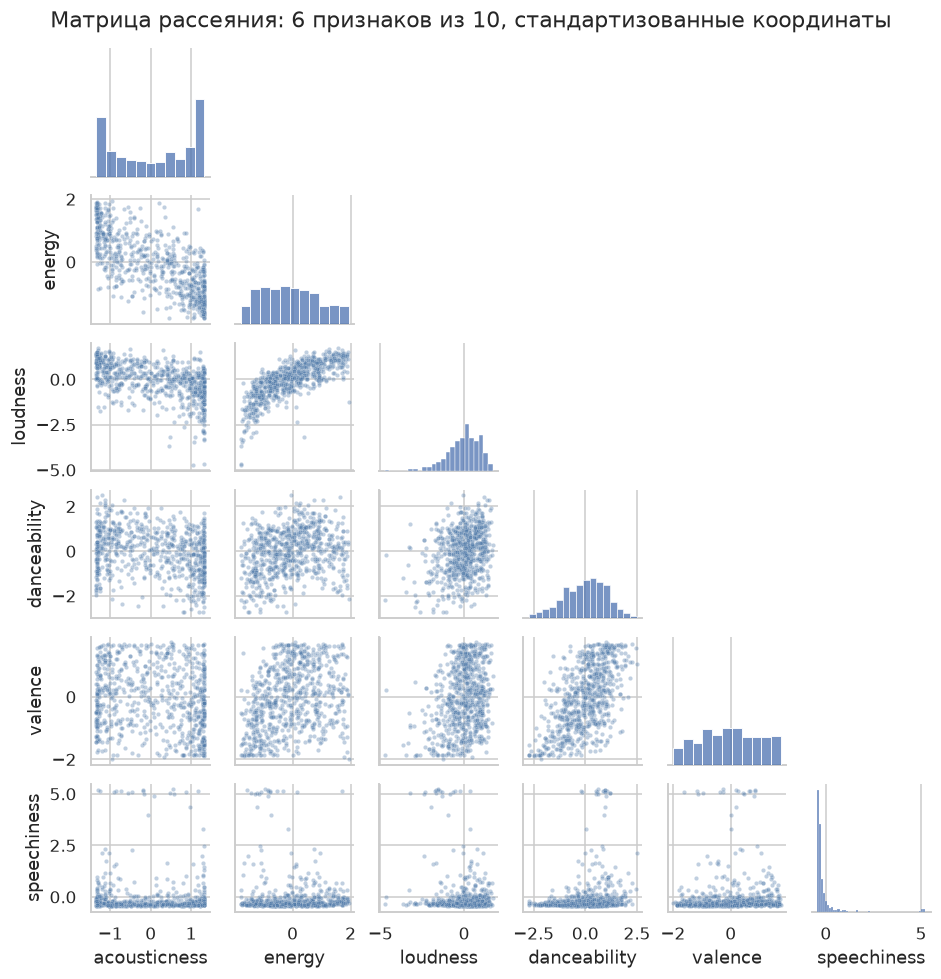

In [7]:
pair_features = ["acousticness", "energy", "loudness", "danceability", "valence", "speechiness"]
pair_view = scaled[pair_features].sample(700, random_state=RANDOM_STATE)
graph = sns.pairplot(pair_view, corner=True, diag_kind="hist", plot_kws={"s": 8, "alpha": 0.35, "color": "#4C78A8"}, height=1.45)
graph.fig.suptitle(
    "Матрица рассеяния: 6 признаков из 10, стандартизованные координаты",
    y=1.02,
)
graph.fig.savefig(FIGURES / "04_матрица_рассеяния.png", bbox_inches="tight")
print("Сохранён график:", "04_матрица_рассеяния.png")
plt.show()


Матрица построена по 6 признакам из 10: acousticness, energy, loudness, danceability, valence и speechiness, на 700 точках подвыборки. liveness, instrumentalness, tempo и duration_ms на рисунок не вынесены: сетка 10×10 перестаёт читаться. Вывод о форме групп относится к этим шести осям.

На диагонали видны те же формы, что и на исходных гистограммах: speechiness прижат к малому значению с редким хвостом, acousticness растянут. Вне диагонали нет колец, лент и изолированных островов плотности. energy, loudness и acousticness образуют вытянутое облако вдоль одной оси: тихие акустические записи на одном конце, громкие энергичные на другом, середина заполнена. danceability и valence дают второе, более слабое вытяжение. Хвост speechiness стоит особняком от основной массы, но сами точки внутри хвоста лежат кучно.

Отсюда выбор методов. Основная масса — два крупных пересекающихся облака сравнимого размаха, близких к выпуклым. Для такой геометрии подходит K-means: он ищет компактные группы вокруг центров в евклидовой метрике. Метод Уорда минимизирует ту же внутрикластерную дисперсию, но строит дерево вложений, поэтому его удобно сравнить с K-means на одном критерии. Одиночная связь здесь не используется: на вытянутом облаке она склеивает объекты цепочкой. DBSCAN тоже плохо ложится на эту картинку. Между акустическим и энергичным концами нет пустой полосы, плотность меняется плавно, и плотностной алгоритм либо сольёт их в один компонент, либо пометит середину шумом. Маленький речевой хвост DBSCAN, возможно, отделил бы, но два больших музыкальных полюса заданы градиентом, а не разрывом плотности.

Размеры групп заранее не равны, и это не противоречит K-means: от него требуется сходный разброс вокруг центров, а не равная численность. Проверка этого предположения — ниже, по средним расстояниям до центров.


## 4. Ход работы

### 4.1. Число кластеров

Для K-means при каждом k от 2 до 10 запускается `KMeans(n_init=10, random_state=42)`. Десять случайных инициализаций k-means++ оставляют запуск с наименьшей инерцией и снижают риск плохого локального минимума. Инерция — сумма квадратов расстояний до своих центров. Коэффициент силуэта усредняет по объектам величину (b − a) / max(a, b): a — средняя дистанция внутри своего кластера, b — средняя дистанция до ближайшего чужого. Индекс Калинского–Харабаша — отношение межкластерной дисперсии к внутрикластерной с поправкой на число кластеров и число объектов; больше значит лучше. Индекс Дэвиса–Болдина усредняет для каждого кластера сходство с ближайшим соседом, где сходство — сумма разбросов, делённая на расстояние между центрами; меньше значит лучше.

Иерархическое решение считается один раз: связь Уорда по стандартизованной матрице. Для каждого k дерево режется на k групп (`fcluster`, критерий `maxclust`), и на тех же объектах считаются силуэт, Калинский–Харабаш и Дэвис–Болдин.


In [8]:
kmeans_rows = []
for k in K_RANGE:
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = model.fit_predict(X)
    kmeans_rows.append({
        "k": k,
        "инерция": model.inertia_,
        "силуэт": silhouette_score(X, labels),
        "Калинский–Харабаш": calinski_harabasz_score(X, labels),
        "Дэвис–Болдин": davies_bouldin_score(X, labels),
    })
kmeans_k = pd.DataFrame(kmeans_rows)

print("Матрица связей Уорда...")
linkage_matrix = linkage(X, method="ward")
hier_rows = []
for k in K_RANGE:
    labels = fcluster(linkage_matrix, t=k, criterion="maxclust")
    hier_rows.append({
        "k": k,
        "силуэт": silhouette_score(X, labels),
        "Калинский–Харабаш": calinski_harabasz_score(X, labels),
        "Дэвис–Болдин": davies_bouldin_score(X, labels),
    })
hier_k = pd.DataFrame(hier_rows)

save_table(kmeans_k, "подбор_k_kmeans.csv")
save_table(hier_k, "подбор_k_уорд.csv")
display(kmeans_k.style.format({
    "инерция": "{:.1f}",
    "силуэт": "{:.3f}",
    "Калинский–Харабаш": "{:.1f}",
    "Дэвис–Болдин": "{:.3f}",
}).hide(axis="index").set_caption("K-means"))
display(hier_k.style.format({
    "силуэт": "{:.3f}",
    "Калинский–Харабаш": "{:.1f}",
    "Дэвис–Болдин": "{:.3f}",
}).hide(axis="index").set_caption("Иерархическая кластеризация, связь Уорда"))


Матрица связей Уорда...


Сохранена таблица: подбор_k_kmeans.csv
Сохранена таблица: подбор_k_уорд.csv


k,инерция,силуэт,Калинский–Харабаш,Дэвис–Болдин
2,47077.4,0.220,1646.4,1.789
3,41512.2,0.240,1335.4,1.417
4,37217.5,0.167,1223.5,1.644
5,34121.9,0.169,1136.7,1.710
6,31552.3,0.173,1080.8,1.628
7,29349.7,0.165,1043.1,1.612
8,27997.2,0.165,978.5,1.586
9,26695.5,0.165,934.3,1.547
10,25658.7,0.163,890.8,1.543


k,силуэт,Калинский–Харабаш,Дэвис–Болдин
2,0.162,1204.6,2.043
3,0.183,1023.8,1.608
4,0.162,966.8,1.648
5,0.169,905.6,1.571
6,0.143,844.0,1.732
7,0.103,793.5,1.949
8,0.106,752.3,1.901
9,0.110,713.5,1.919
10,0.103,682.1,1.823


Сохранён график: 05_локоть_и_силуэт.png


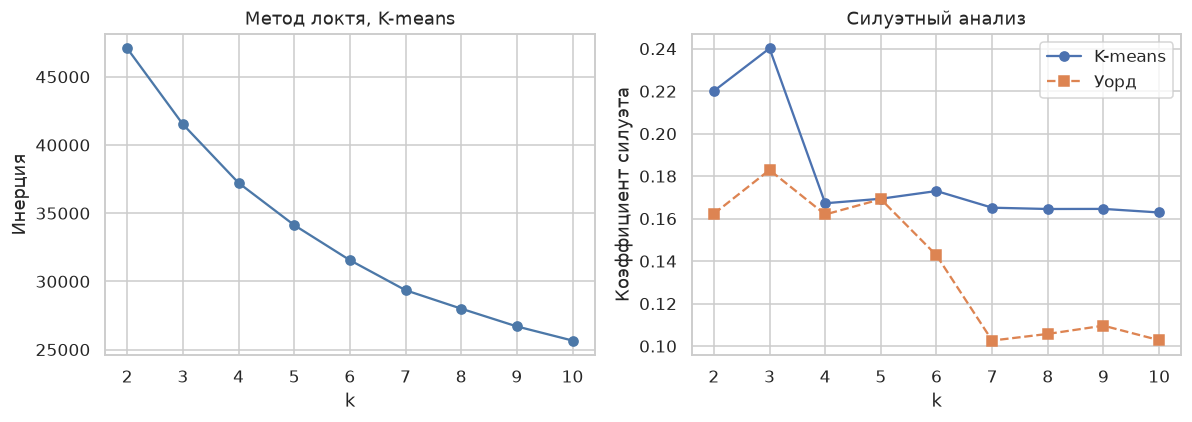

Сохранён график: 06_индексы_качества.png


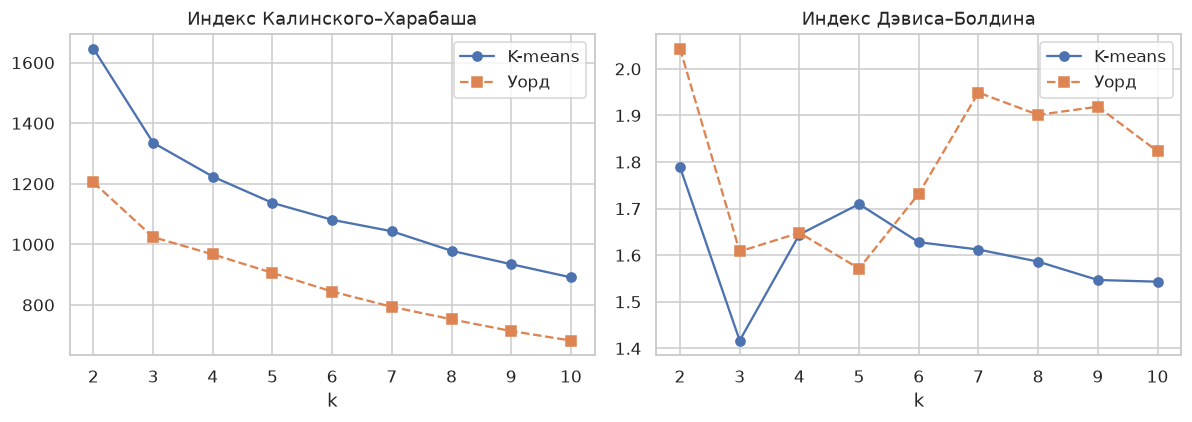

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(kmeans_k["k"], kmeans_k["инерция"], marker="o", color="#4C78A8")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Инерция")
axes[0].set_title("Метод локтя, K-means")
axes[0].set_xticks(list(K_RANGE))

axes[1].plot(kmeans_k["k"], kmeans_k["силуэт"], marker="o", label="K-means")
axes[1].plot(hier_k["k"], hier_k["силуэт"], marker="s", linestyle="--", label="Уорд")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Коэффициент силуэта")
axes[1].set_title("Силуэтный анализ")
axes[1].set_xticks(list(K_RANGE))
axes[1].legend()
fig.tight_layout()
save_show("05_локоть_и_силуэт.png")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(kmeans_k["k"], kmeans_k["Калинский–Харабаш"], marker="o", label="K-means")
axes[0].plot(hier_k["k"], hier_k["Калинский–Харабаш"], marker="s", linestyle="--", label="Уорд")
axes[0].set_title("Индекс Калинского–Харабаша")
axes[1].plot(kmeans_k["k"], kmeans_k["Дэвис–Болдин"], marker="o", label="K-means")
axes[1].plot(hier_k["k"], hier_k["Дэвис–Болдин"], marker="s", linestyle="--", label="Уорд")
axes[1].set_title("Индекс Дэвиса–Болдина")
for axis in axes:
    axis.set_xlabel("k")
    axis.set_xticks(list(K_RANGE))
    axis.legend()
fig.tight_layout()
save_show("06_индексы_качества.png")


Инерция падает плавно: с 47 077 при k = 2 до 25 659 при k = 10. Резкого излома нет. Это ожидаемо, если группы перекрываются и каждое новое деление ещё немного уменьшает разброс. Крутизна снижается постепенно, заметнее после k = 7, но к этому месту силуэт уже хуже, чем при трёх кластерах.

Критерии числа кластеров не согласованы.

- Индекс Калинского–Харабаша максимален при k = 2: 1646 против 1335 при k = 3. Он предпочитает два кластера.
- Силуэт обоих методов максимален при k = 3: 0,240 у K-means и 0,183 у Уорда. При k = 2 силуэт K-means равен 0,220, при k = 4 падает до 0,167.
- Индекс Дэвиса–Болдина у K-means минимален при k = 3 и равен 1,417.
- У метода Уорда индекс Дэвиса–Болдина минимален не при k = 3, а при k = 5: 1,571 против 1,608 при k = 3. Это ещё одно противоречие. При k = 5 силуэт Уорда уже хуже, чем при k = 3.

k = 3 выбран по силуэту обоих методов, по индексу Дэвиса–Болдина метода K-means и по дендрограмме, где третьим элементом отделяется речевая ветвь. Индекс Калинского–Харабаша и индекс Дэвиса–Болдина метода Уорда с этим выбором не совпадают.


### 4.2. Итоговые модели и метрики качества

Оба метода применяются при k = 3 к одной стандартизованной подвыборке. Метки переименовываются по центрам, потому что номера кластеров сами по себе ничего не значат: группа с наибольшей speechiness называется «Речевые», из двух оставшихся группа с большей energy — «Энергичные», вторая — «Акустические».

Внешние индексы относительно истинного класса не считаются: жанровой разметки нет. Adjusted Rand index и NMI ниже сравнивают два полученных разбиения между собой. ARI равен 1 при полном совпадении, 0 при совпадении на уровне случайного, и может быть отрицательным. Это не проверка правильности кластеров.


In [10]:
def cluster_names(labels, frame):
    scores = frame.assign(cluster=labels).groupby("cluster")[["speechiness", "energy"]].mean()
    speech = scores["speechiness"].idxmax()
    rest = scores.drop(index=speech)
    energetic = rest["energy"].idxmax()
    acoustic = rest["energy"].idxmin()
    return {speech: "Речевые", energetic: "Энергичные", acoustic: "Акустические"}


def geometry(features, labels):
    rows = []
    centers = []
    names = []
    sil_values = silhouette_samples(features, labels)
    for name in CLUSTER_ORDER:
        mask = labels == name
        points = features[mask]
        center = points.mean(axis=0)
        distances = np.linalg.norm(points - center, axis=1)
        rows.append({
            "кластер": name,
            "размер": int(mask.sum()),
            "доля": mask.mean(),
            "средняя дистанция до центра": distances.mean(),
            "медианная дистанция до центра": np.median(distances),
            "максимальная дистанция до центра": distances.max(),
            "сумма квадратов дистанций": np.sum(distances ** 2),
            "средний силуэт": sil_values[mask].mean(),
        })
        centers.append(center)
        names.append(name)
    centers = np.vstack(centers)
    distance_matrix = pd.DataFrame(
        np.linalg.norm(centers[:, None, :] - centers[None, :, :], axis=2),
        index=names,
        columns=names,
    )
    return pd.DataFrame(rows), distance_matrix


kmeans_model = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE)
kmeans_raw = kmeans_model.fit_predict(X)
kmeans_map = cluster_names(kmeans_raw, sample)
kmeans_labels = pd.Series(kmeans_raw).map(kmeans_map).to_numpy()

hier_raw = fcluster(linkage_matrix, t=3, criterion="maxclust")
hier_map = cluster_names(hier_raw, sample)
hier_labels = pd.Series(hier_raw).map(hier_map).to_numpy()

kmeans_within, kmeans_between = geometry(X, kmeans_labels)
hier_within, hier_between = geometry(X, hier_labels)

metrics = pd.DataFrame({
    "K-means": [
        silhouette_score(X, kmeans_labels),
        calinski_harabasz_score(X, kmeans_labels),
        davies_bouldin_score(X, kmeans_labels),
        kmeans_model.inertia_,
    ],
    "Уорд": [
        silhouette_score(X, hier_labels),
        calinski_harabasz_score(X, hier_labels),
        davies_bouldin_score(X, hier_labels),
        np.nan,
    ],
}, index=["Силуэт", "Калинский–Харабаш", "Дэвис–Болдин", "Инерция"])
save_table(metrics, "сравнение_методов.csv")
display(metrics.style.format("{:.3f}", na_rep="—"))
agreement_metrics = pd.DataFrame({
    "значение": [
        adjusted_rand_score(kmeans_labels, hier_labels),
        normalized_mutual_info_score(kmeans_labels, hier_labels),
        (kmeans_labels == hier_labels).mean(),
    ]
}, index=["ARI двух разбиений", "NMI двух разбиений", "доля совпавших имён"])
display(agreement_metrics.round(3))
save_table(agreement_metrics.round(3), "согласованность_методов.csv")

print("K-means: размер, компактность, силуэт по кластерам")
display(kmeans_within.style.format({
    "доля": "{:.1%}",
    "средняя дистанция до центра": "{:.3f}",
    "медианная дистанция до центра": "{:.3f}",
    "максимальная дистанция до центра": "{:.3f}",
    "сумма квадратов дистанций": "{:.1f}",
    "средний силуэт": "{:.3f}",
}).hide(axis="index"))
print("Расстояния между центрами K-means в стандартизованном пространстве")
save_table(kmeans_within, "геометрия_kmeans.csv")
display(kmeans_between.round(3))
save_table(kmeans_between.round(3), "расстояния_центров_kmeans.csv")

print("Уорд: размер, компактность, силуэт по кластерам")
display(hier_within.style.format({
    "доля": "{:.1%}",
    "средняя дистанция до центра": "{:.3f}",
    "медианная дистанция до центра": "{:.3f}",
    "максимальная дистанция до центра": "{:.3f}",
    "сумма квадратов дистанций": "{:.1f}",
    "средний силуэт": "{:.3f}",
}).hide(axis="index"))
print("Расстояния между центрами Уорда в стандартизованном пространстве")
save_table(hier_within, "геометрия_уорд.csv")
display(hier_between.round(3))
save_table(hier_between.round(3), "расстояния_центров_уорд.csv")

agreement = (kmeans_labels == hier_labels).mean()
print(f"Доля объектов с одинаковым именем кластера: {agreement:.1%}")
crosstab = pd.crosstab(
    pd.Series(kmeans_labels, name="K-means"),
    pd.Series(hier_labels, name="Уорд"),
).reindex(index=CLUSTER_ORDER, columns=CLUSTER_ORDER)
display(crosstab)
save_table(crosstab, "сопряжённость.csv")


Сохранена таблица: сравнение_методов.csv


,K-means,Уорд
Силуэт,0.240,0.183
Калинский–Харабаш,1335.413,1023.761
Дэвис–Болдин,1.417,1.608
Инерция,41512.227,—


,значение
ARI двух разбиений,0.426
NMI двух разбиений,0.460
доля совпавших имён,0.816


Сохранена таблица: согласованность_методов.csv
K-means: размер, компактность, силуэт по кластерам


кластер,размер,доля,средняя дистанция до центра,медианная дистанция до центра,максимальная дистанция до центра,сумма квадратов дистанций,средний силуэт
Акустические,2231,37.2%,2.636,2.463,6.082,16996.2,0.192
Энергичные,3553,59.2%,2.426,2.279,6.461,23087.3,0.258
Речевые,216,3.6%,2.391,2.176,5.991,1428.6,0.448


Расстояния между центрами K-means в стандартизованном пространстве
Сохранена таблица: геометрия_kmeans.csv


... (4 outputs left out)

,Акустические,Энергичные,Речевые
Акустические,0.000,2.605,5.577
Энергичные,2.605,0.000,5.968
Речевые,5.577,5.968,0.000


Сохранена таблица: расстояния_центров_уорд.csv
Доля объектов с одинаковым именем кластера: 81.6%


Уорд,Акустические,Энергичные,Речевые
K-means,,,
Акустические,2125,106,0
Энергичные,961,2592,0
Речевые,34,4,178


Сохранена таблица: сопряжённость.csv


K-means при k = 3 получает силуэт 0,240, индекс Калинского–Харабаша 1335 и индекс Дэвиса–Болдина 1,417. Уорд на тех же объектах: 0,183, 1024 и 1,608. По всем трём внутренним метрикам центроидное разбиение лучше. Инерция Уорда в таблице не приводится: у иерархического дерева нет того же итеративного критерия, что у K-means, и подставлять чужую сумму квадратов было бы некорректно. Суммы квадратов дистанций до своих центров по кластерам в таблицах выше сопоставимы напрямую, потому что посчитаны в одном пространстве.

Силуэт 0,24 — слабая структура. Типичное правило таково: значения около 0,25 и ниже означают, что заметная часть объектов лежит у границы. Индекс Дэвиса–Болдина больше единицы говорит о том же: разброс внутри соседних кластеров больше, чем зазор между их центрами.

Средняя дистанция до центра у K-means составляет примерно 2,64 у акустических, 2,43 у энергичных и 2,39 у речевых. Радиусы близки, так что предположение K-means о сравнимом разбросе здесь выполняется, хотя численности разные: 37%, 59% и 3,6%. Ближайшие центры, акустический и энергичный, разведены на 3,06. Это лишь немногим больше типичной внутрикластерной дистанции, поэтому два больших облака перекрываются. Речевой центр отстоит на 5,34 и 5,47. Его средний силуэт 0,45, тогда как у акустического только 0,19: отделена именно речевая группа, а не вся тройка одинаково.

У Уорда речевая группа ещё компактнее по силуэту (0,55), но меньше (178 против 216). За это заплатил акустический кластер: в него попало 3120 объектов, и средний силуэт этой группы 0,09. Уорд оставил более широкую «неэнергичную» массу.

ARI двух разбиений равен 0,426. Это умеренное согласие: методы видят одни и те же полюса, но не проводят одну и ту же границу. NMI равен 0,460. Имена совпадают у 81,6% объектов; простая доля завышена из-за двух крупных классов, и ARI как раз снимает случайное совпадение. Уорд сдвигает границу в сторону энергичных: 961 объект, который K-means относит к энергичным, Уорд относит к акустическим. Ещё 106 объектов расходятся в обратную сторону. Речевое ядро общее: все 178 речевых объектов Уорда лежат внутри речевого кластера K-means.


### 4.3. Влияние параметра k и устойчивость

Параметр, который задаётся исследователем в K-means, — число кластеров. Таблица раздела 4.1 уже есть кривая его влияния. При росте k инерция монотонно снижается, потому что у точек появляется более близкий центр; сама по себе она не выбирает модель. Силуэт после k = 3 не восстанавливается. Дэвис–Болдин после минимума при k = 3 тоже ухудшается и лишь к k = 9–10 немного снижается за счёт дробления, не возвращаясь к качеству тройного решения. Дополнительные кластеры режут уже перекрывающиеся музыкальные полюса, а не отделяют новый компактный тип записи.

Отдельно проверена устойчивость инициализации. Та же модель K-means при k = 3 и `n_init=10` запущена с пятью разными `random_state`. Согласованность с опорным решением измеряется ARI.

Центры проверены и на всей очищенной таблице, без подвыборки. Силуэт на 168 тысячах строк не считается: он квадратичен. Сравниваются размеры групп и средние исходных признаков.


In [11]:
reference = kmeans_labels
stability = []
for seed in range(5):
    labels = KMeans(n_clusters=3, n_init=10, random_state=seed).fit_predict(X)
    named = pd.Series(labels).map(cluster_names(labels, sample)).to_numpy()
    stability.append({
        "random_state": seed,
        "ARI с опорным решением": adjusted_rand_score(reference, named),
    })
stability_table = pd.DataFrame(stability)
save_table(stability_table, "устойчивость_инициализации.csv")
display(stability_table.style.format({"ARI с опорным решением": "{:.3f}"}).hide(axis="index"))

full_scaler = StandardScaler()
X_full = full_scaler.fit_transform(clean[AUDIO_FEATURES])
full_raw = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit_predict(X_full)
full_named = pd.Series(full_raw).map(cluster_names(full_raw, clean)).to_numpy()
full_profile = clean.assign(кластер=full_named).groupby("кластер")[AUDIO_FEATURES].mean().reindex(CLUSTER_ORDER)
full_sizes = pd.Series(full_named).value_counts().reindex(CLUSTER_ORDER)
full_profile.insert(0, "размер", full_sizes.to_numpy())
print("K-means по всей очищенной таблице")
display(full_profile.round(3))
save_table(full_profile.round(3), "центры_полная_выборка.csv")
print("Доли на полной таблице:")
display((pd.Series(full_named).value_counts(normalize=True).reindex(CLUSTER_ORDER) * 100).round(1).rename("доля, %").to_frame())


Сохранена таблица: устойчивость_инициализации.csv


random_state,ARI с опорным решением
0,0.988
1,0.990
2,0.988
3,0.988
4,0.985


K-means по всей очищенной таблице


,размер,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,duration_ms
кластер,,,,,,,,,,,
Акустические,64489,0.851,0.447,0.236,0.325,0.189,-15.717,0.057,107.705,0.396,214553.043
Энергичные,97890,0.265,0.594,0.662,0.065,0.209,-8.150,0.081,123.756,0.622,231101.028
Речевые,5710,0.539,0.677,0.256,0.014,0.308,-18.177,0.856,109.158,0.540,153946.751


Сохранена таблица: центры_полная_выборка.csv
Доли на полной таблице:


,"доля, %"
Акустические,38.4
Энергичные,58.2
Речевые,3.4


ARI между разными инициализациями около 0,985–0,990. При `n_init=10` решение K-means для этих данных практически не зависит от стартовых центров.

На полной таблице 168 089 треков группы сохраняют и состав, и доли. Речевых около 3,4% (в подвыборке 3,6%), энергичных около 58% (59%), акустических около 38% (37%). Средние acousticness, energy, loudness и speechiness совпадают с центрами подвыборки до второго знака. Подвыборка не выдумала структуру, которой нет в полном массиве.

Дополнительная проверка состава признаков, уже не параметра k: если убрать liveness, tempo и duration_ms, то есть три оси с самой слабой связью с полученным разрезом, силуэт K-means при k = 3 вырастает примерно с 0,24 до 0,32, а размеры групп остаются прежними. Эти признаки после стандартизации не формируют свои кластеры и слегка размывают расстояние. В основной модели они оставлены, потому что это штатные аудиопризнаки датасета; вывод о трёх группах от них не зависит.


In [12]:
core_features = [
    "acousticness", "danceability", "energy", "instrumentalness",
    "loudness", "speechiness", "valence",
]
X_core = StandardScaler().fit_transform(sample[core_features])
core_raw = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit_predict(X_core)
core_named = pd.Series(core_raw).map(cluster_names(core_raw, sample)).to_numpy()
core_check = pd.DataFrame({
    "модель": ["все 10 признаков", "без liveness, tempo, duration_ms"],
    "силуэт": [
        silhouette_score(X, kmeans_labels),
        silhouette_score(X_core, core_named),
    ],
    "Калинский–Харабаш": [
        calinski_harabasz_score(X, kmeans_labels),
        calinski_harabasz_score(X_core, core_named),
    ],
    "Дэвис–Болдин": [
        davies_bouldin_score(X, kmeans_labels),
        davies_bouldin_score(X_core, core_named),
    ],
    "ARI с основной моделью": [
        1.0,
        adjusted_rand_score(kmeans_labels, core_named),
    ],
})
display(core_check.round(3))
save_table(core_check.round(3), "проверка_состава_признаков.csv")
display(pd.Series(core_named).value_counts().reindex(CLUSTER_ORDER).rename("размер без трёх признаков").to_frame())


,модель,силуэт,Калинский–Харабаш,Дэвис–Болдин,ARI с основной моделью
0,все 10 признаков,0.240,1335.413,1.417,1.000
1,"без liveness, tempo, duration_ms",0.322,2225.852,1.092,0.912


Сохранена таблица: проверка_состава_признаков.csv


,размер без трёх признаков
Акустические,2276
Энергичные,3512
Речевые,212


## 5. Визуализация результатов

Дендрограмма показывает последние 20 слияний, иначе 6000 листьев сливаются в сплошную полосу. Высота слияния — прирост внутрикластерной дисперсии Уорда. Пунктир стоит между вторым и третьим слиянием сверху и пересекает ровно три ветви. Левая — энергичное крыло. Короткая средняя ветвь из 178 объектов — речевая группа: она присоединяется к остальным выше пунктира и отдельно от широкой акустической массы справа. Внутри акустической ветви развилки уже заметно ниже разреза. Картина согласована с выбором k = 3.


Сохранён график: 07_дендрограмма.png


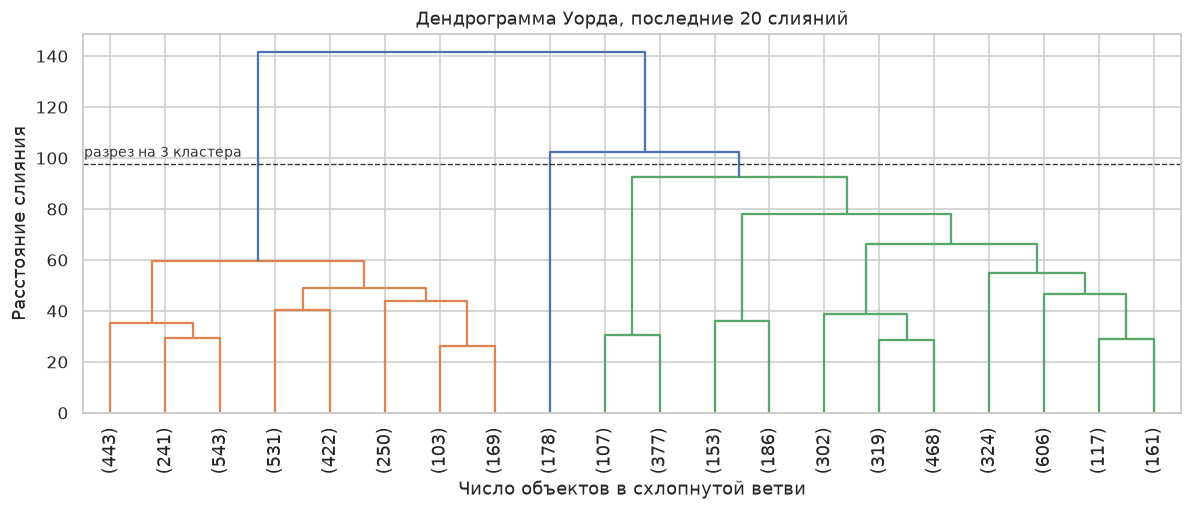

In [13]:
fig, axis = plt.subplots(figsize=(11, 4.8))
cut_height = (linkage_matrix[-2, 2] + linkage_matrix[-3, 2]) / 2
dendrogram(
    linkage_matrix,
    truncate_mode="lastp",
    p=20,
    leaf_rotation=90,
    color_threshold=cut_height,
    ax=axis,
)
axis.axhline(cut_height, color="#333333", linestyle="--", linewidth=0.9)
axis.text(0.2, cut_height + 3, "разрез на 3 кластера", fontsize=9, color="#333333")
axis.set_title("Дендрограмма Уорда, последние 20 слияний")
axis.set_xlabel("Число объектов в схлопнутой ветви")
axis.set_ylabel("Расстояние слияния")
fig.tight_layout()
save_show("07_дендрограмма.png")


Доля дисперсии: PC1 30.6%, PC2 15.6%, вместе 46.2%


,PC1,PC2
acousticness,-0.446,-0.214
danceability,0.299,-0.480
energy,0.500,0.228
instrumentalness,-0.297,0.157
liveness,0.057,0.007
loudness,0.480,0.177
speechiness,0.008,-0.452
tempo,0.195,0.088
valence,0.319,-0.405
duration_ms,0.023,0.489


Сохранена таблица: нагрузки_pca.csv


Сохранён график: 08_нагрузки_pca.png


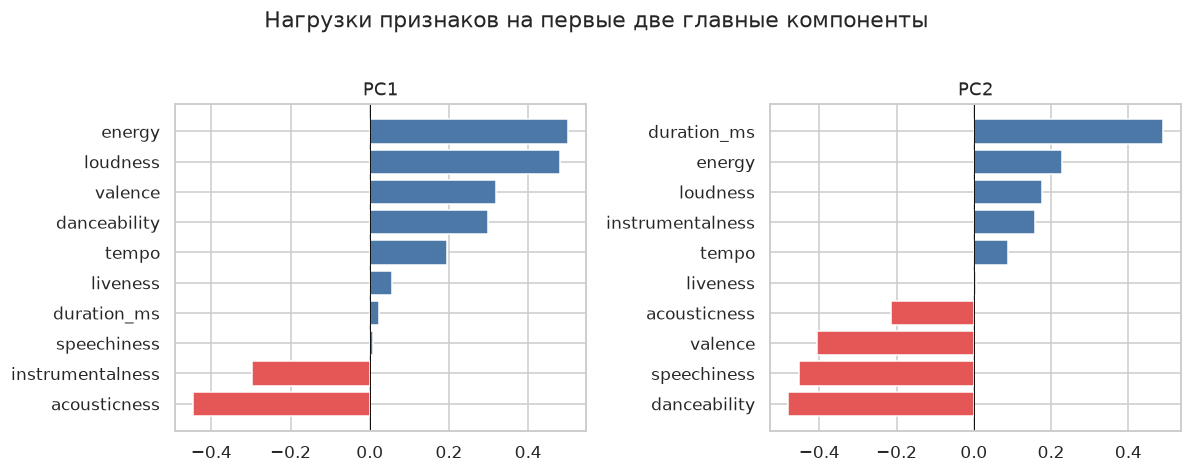

Сохранён график: 09_кластеры_pca.png


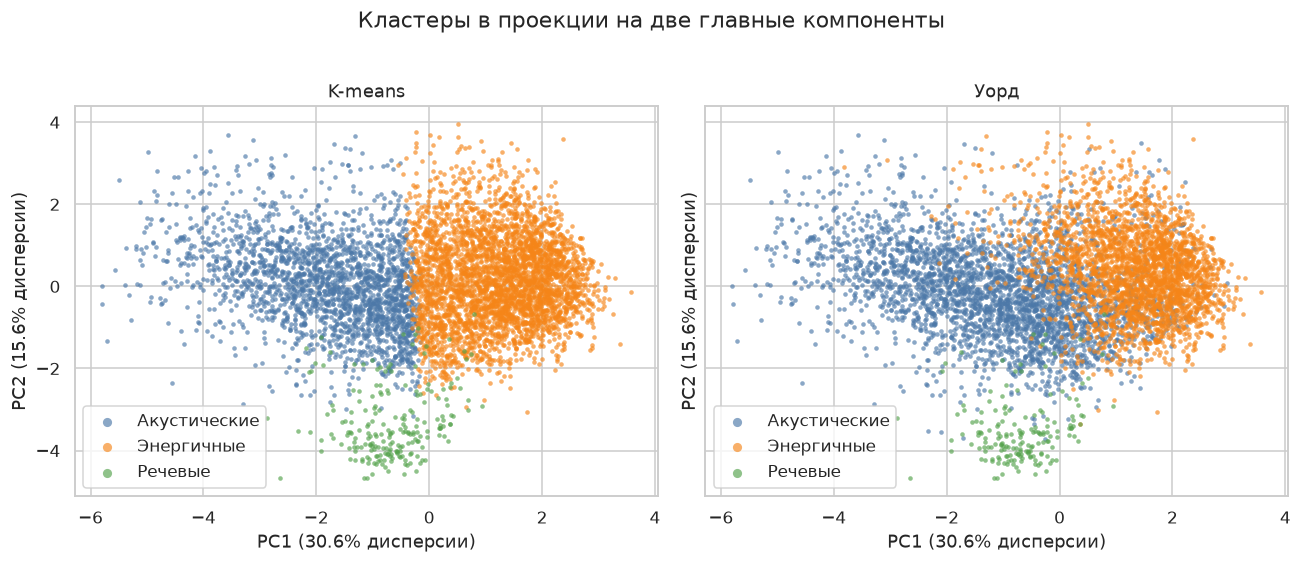

In [14]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
xy = pca.fit_transform(X)
loadings = pd.DataFrame(
    pca.components_.T,
    index=AUDIO_FEATURES,
    columns=["PC1", "PC2"],
)
explained = pca.explained_variance_ratio_
print(f"Доля дисперсии: PC1 {explained[0]:.1%}, PC2 {explained[1]:.1%}, вместе {explained.sum():.1%}")
display(loadings.round(3))
save_table(loadings.round(3), "нагрузки_pca.csv")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for axis, component in zip(axes, ["PC1", "PC2"]):
    ordered = loadings[component].sort_values()
    colors = ["#E45756" if value < 0 else "#4C78A8" for value in ordered]
    axis.barh(ordered.index, ordered.values, color=colors)
    axis.axvline(0, color="black", lw=0.6)
    axis.set_title(component)
fig.suptitle("Нагрузки признаков на первые две главные компоненты", y=1.02)
fig.tight_layout()
save_show("08_нагрузки_pca.png")

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for axis, labels, title in (
    (axes[0], kmeans_labels, "K-means"),
    (axes[1], hier_labels, "Уорд"),
):
    for name in ["Акустические", "Энергичные", "Речевые"]:
        mask = labels == name
        axis.scatter(
            xy[mask, 0],
            xy[mask, 1],
            s=9,
            alpha=0.65,
            c=PALETTE[name],
            label=name,
            linewidths=0,
        )
    axis.set_title(title)
    axis.set_xlabel(f"PC1 ({explained[0]:.1%} дисперсии)")
    axis.set_ylabel(f"PC2 ({explained[1]:.1%} дисперсии)")
    axis.legend(markerscale=2, frameon=True)
fig.suptitle("Кластеры в проекции на две главные компоненты", y=1.02)
fig.tight_layout()
save_show("09_кластеры_pca.png")


Первые две компоненты удерживают 46,2% дисперсии. Это мало: больше половины разброса остаётся вне рисунка. Плоскость — схема, а не полное изображение расстояний. Шесть компонент нужны, чтобы пройти около 85%.

PC1 противопоставляет energy и loudness признаку acousticness: это тот же градиент, что на диаграммах рассеяния. PC2 противопоставляет длительность связке speechiness и danceability. Речевые точки уходят вниз по PC2, потому что у speechiness на этой компоненте отрицательная нагрузка, а сами записи короче. На графике два больших кластера — левое и правое крыло одного облака с широкой зоной смешения посередине. Речевая группа видна как отдельный нижний хвост. У K-means этот хвост чуть шире, у Уорда он короче и плотнее, зато граница левого и правого крыла сдвинута. Так выглядит расхождение, которое уже показал ARI 0,426.


Центры K-means в исходных единицах


,размер,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,duration_ms,year,popularity,explicit,mode
кластер,,,,,,,,,,,,,,,
Акустические,2231,0.851,0.442,0.228,0.320,0.184,-15.868,0.056,106.930,0.381,215389.322,1962.602,19.878,0.003,0.721
Энергичные,3553,0.278,0.593,0.657,0.073,0.212,-8.163,0.079,123.354,0.620,230540.707,1988.534,40.868,0.111,0.697
Речевые,216,0.554,0.671,0.247,0.007,0.330,-18.253,0.860,111.183,0.534,164748.569,1943.713,4.708,0.472,0.685


Сохранена таблица: центры_kmeans.csv
Центры Уорда в исходных единицах


,размер,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,duration_ms,year,popularity,explicit,mode
кластер,,,,,,,,,,,,,,,
Акустические,3120,0.779,0.487,0.319,0.243,0.219,-13.963,0.065,112.403,0.484,205515.395,1965.318,22.338,0.009,0.735
Энергичные,2702,0.179,0.591,0.687,0.080,0.183,-7.920,0.083,122.399,0.580,245884.659,1993.544,44.561,0.138,0.675
Речевые,178,0.495,0.679,0.239,0.001,0.326,-19.013,0.928,109.181,0.521,166528.202,1940.006,2.646,0.567,0.669


Сохранена таблица: центры_уорд.csv


Сохранён график: 10_профили_кластеров.png


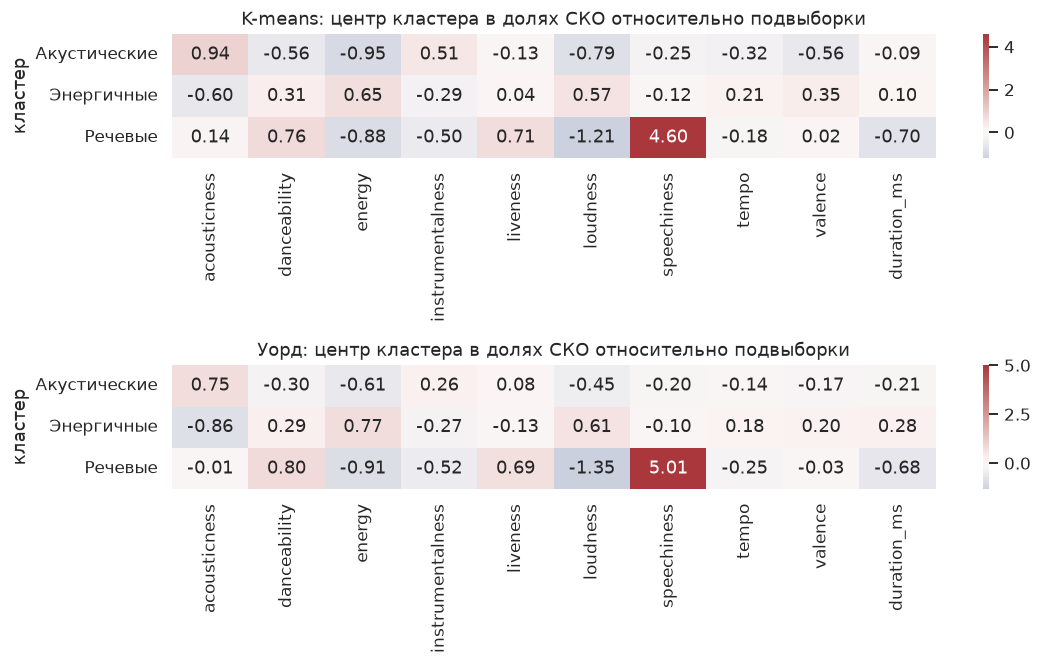

,доля межкластерной дисперсии
speechiness,0.794
energy,0.617
acousticness,0.541
loudness,0.479
danceability,0.193
valence,0.187
instrumentalness,0.154
tempo,0.067
duration_ms,0.026
liveness,0.025


Сохранена таблица: значимость_признаков.csv


In [15]:
profile_columns = AUDIO_FEATURES + ["year", "popularity", "explicit", "mode"]


def original_profile(frame, labels):
    grouped = frame.assign(кластер=labels).groupby("кластер")[profile_columns].mean().reindex(CLUSTER_ORDER)
    sizes = pd.Series(labels).value_counts().reindex(CLUSTER_ORDER)
    grouped.insert(0, "размер", sizes.to_numpy())
    return grouped


print("Центры K-means в исходных единицах")
kmeans_centers = original_profile(sample, kmeans_labels).round(3)
display(kmeans_centers)
save_table(kmeans_centers, "центры_kmeans.csv")
print("Центры Уорда в исходных единицах")
hier_centers = original_profile(sample, hier_labels).round(3)
display(hier_centers)
save_table(hier_centers, "центры_уорд.csv")


def z_profile(frame, labels):
    means = frame.assign(кластер=labels).groupby("кластер")[AUDIO_FEATURES].mean().reindex(CLUSTER_ORDER)
    return (means - frame[AUDIO_FEATURES].mean()) / frame[AUDIO_FEATURES].std(ddof=0)


fig, axes = plt.subplots(2, 1, figsize=(10.5, 6.2))
for axis, labels, title in (
    (axes[0], kmeans_labels, "K-means"),
    (axes[1], hier_labels, "Уорд"),
):
    sns.heatmap(z_profile(sample, labels), cmap="vlag", center=0, annot=True, fmt=".2f", ax=axis)
    axis.set_title(f"{title}: центр кластера в долях СКО относительно подвыборки")
fig.tight_layout()
save_show("10_профили_кластеров.png")

overall = X.mean(axis=0)
total_ss = ((X - overall) ** 2).sum(axis=0)
between_ss = np.zeros(X.shape[1])
for name in CLUSTER_ORDER:
    mask = kmeans_labels == name
    between_ss += mask.sum() * (X[mask].mean(axis=0) - overall) ** 2
eta = pd.Series(between_ss / total_ss, index=AUDIO_FEATURES, name="доля межкластерной дисперсии").sort_values(ascending=False)
display(eta.round(3).to_frame())
save_table(eta.round(3).to_frame(), "значимость_признаков.csv")


Центры ниже прочитаны по K-means. Решение Уорда сдвигает границу, но называет те же три типа. Год и популярность в кластеризацию не входили: разница по ним — следствие, а не входной признак.

**Акустические**, около 37% подвыборки. acousticness 0,85, energy 0,23, loudness около −16 дБ, instrumentalness 0,32, valence 0,38, темп около 107. Это более тихие, чаще акустические и частично инструментальные записи, с более спокойной окраской. Средний год около 1963, средняя популярность около 20, доля explicit около 0,3%. Средний силуэт 0,19: группа сборная, в ней и акустический вокал, и инструментальные записи.

**Энергичные**, около 59%. acousticness 0,28, energy 0,66, loudness около −8 дБ, danceability 0,59, valence 0,62, темп около 123, instrumentalness всего 0,07. Это более громкая, танцевальная и мажорная по настроению музыка. Средний год около 1989, популярность около 41, explicit около 11%. Группа — основной массив датасета. Силуэт 0,26: полюс есть, но граница с акустическим крылом рыхлая.

**Речевые**, 216 треков, 3,6%. speechiness 0,86 при том, что у двух других групп она равна 0,06 и 0,08. Записи короче (около 165 с), тише (около −18 дБ), при невысокой энергии. Средняя популярность около 5. Год в среднем около 1944, медиана 1940; три четверти объектов относятся к периоду до 1950 года. Примеры в таблице — главы аудиокниг и разговорные номера, а не отдельный музыкальный жанр. Поле `year` у аудиокниг — год литературного произведения, а не год записи, поэтому средний год нельзя читать как дату студийной сессии. Флаг explicit около 47% здесь тоже свойство этих записей, а не признак рэпа: в кластер попадают единичные речевые песни, но ядро составляют чтение и монологи. Силуэт 0,45 — единственная действительно отделившаяся группа. Доля межкластерной дисперсии speechiness равна 0,794. Это не значит, что речь — главный признак всего датасета: значение велико, потому что речевая группа мала, но резко отличается от двух других. Малая далеко отстоящая группа забирает большую долю межкластерной суммы квадратов по этой оси. Дальше разрез держат energy (0,62), acousticness (0,54) и loudness (0,48). tempo, duration_ms и liveness дают 0,07, 0,03 и 0,03: на тройное решение они почти не влияют.


In [16]:
labeled = sample.assign(кластер=kmeans_labels)
columns = ["кластер", "year", "name", "artists", "speechiness", "energy", "acousticness", "popularity"]
examples = []
for name in CLUSTER_ORDER:
    mask = labeled["кластер"].to_numpy() == name
    center = X[mask].mean(axis=0)
    distance = np.linalg.norm(X[mask] - center, axis=1)
    nearest = labeled.index.to_numpy()[mask][np.argsort(distance)[:5]]
    examples.append(labeled.loc[nearest, columns])
display(pd.concat(examples, ignore_index=True))

speech_year = labeled.loc[labeled["кластер"] == "Речевые", "year"]
print(speech_year.describe().round(1).to_string())
print(f"доля речевых записей с year < 1950: {(speech_year < 1950).mean():.1%}")


,кластер,year,name,artists,speechiness,energy,acousticness,popularity
0,Акустические,1935,They Can't Take That Away from Me,['Fred Astaire'],0.0359,0.137,0.977,22
1,Акустические,1948,Ankhiyan Taras Rahi Un Bin,['Meena Kumari'],0.0567,0.124,0.989,0
2,Акустические,1963,Y Hablame - Bolero,['Javier Solís'],0.0348,0.116,0.942,22
3,Акустические,1964,Love Comes But Once,['Bert Kaempfert'],0.0290,0.289,0.867,25
4,Акустические,1955,Abhathou an Aynain,['Fairuz'],0.0430,0.129,0.990,11
5,Энергичные,1967,Just Dropped In (To See What Condition My Cond...,['The First Edition'],0.0582,0.551,0.181,57
6,Энергичные,1968,Greasy Heart,['Jefferson Airplane'],0.0395,0.658,0.260,29
7,Энергичные,1973,El Vendedor - (Remasterizado),['Mocedades'],0.0580,0.643,0.221,37
8,Энергичные,1981,After the Glitter Fades - 2016 Remaster,['Stevie Nicks'],0.0271,0.569,0.434,37
9,Энергичные,1989,Hide Your Heart,['KISS'],0.0617,0.846,0.306,38


count     216.0
mean     1943.7
std        18.2
min      1926.0
25%      1931.0
50%      1940.0
75%      1949.2
max      2018.0
доля речевых записей с year < 1950: 75.0%


Сравнение методов на одном рисунке и в одной таблице центров сводится к трём наблюдениям.

1. Оба метода отделяют речевые записи от музыки. Уорд берёт более строгое ядро (178 против 216) и получает у него более высокий силуэт.
2. Оба метода делят остальную музыку по оси «акустика и тихая запись — энергия и громкость». Уорд сдвигает границу в сторону энергичных: 961 объект, энергичный по K-means, у Уорда попадает в акустические. Из-за этого акустический кластер K-means однороднее: его силуэт 0,19 против 0,09 у широкой группы Уорда. ARI 0,426 — умеренное согласие, а не совпадение разбиений.
3. Поэтому при общем сюжете K-means выигрывает по сводным внутренним метрикам. Уорд полезен как независимая проверка, что тройная структура не является артефактом случайных центров: дендрограмма приходит к тем же трём ветвям.


## 6. Заключение

Датасет из 170 653 треков подходит для кластеризации: класса нет, пропусков нет, а аудиопризнаки образуют интерпретируемые оси. Нормальному закону не следует ни один признак. Оценки нормальности сняты с разных выборок: W и p-value Шапиро–Уилка — с 5000 строк, асимметрия и эксцесс — со всех 170 653. acousticness и energy плосковершинны, speechiness, instrumentalness и liveness нулевые с тяжёлым хвостом, длительность сильно скошена. Хвосты речевых и инструментальных признаков сохранены. Удалены 2564 строки, 1,5% файла: среди них 143 строки с `tempo = 0` и `danceability = 0`, это дефект Spotify API, а не пустые треки, и объекты длиннее 10 минут, включая аудиокнигу около 90 минут.

Стандартизация обязательна, но не потому, что длительность «информативнее» остальных признаков. `raw_variance_share` — артефакт единиц: дисперсия `duration_ms` считается в мс² и забирает 99,999994% (при округлении до четырёх знаков это 99,9999%; при меньшем числе знаков доля выглядит как 100%) сырой дисперсии. `StandardScaler` выбран потому, что K-means и Уорд сравнивают евклидовы дисперсии, а не ранги и не минимумы с максимумами.

Матрица рассеяния построена по 6 признакам из 10 и показывает вытянутое перекрывающееся облако и отдельный речевой хвост. Под эту форму взяты K-means с десятью инициализациями и иерархическая кластеризация Уорда. Критерии k противоречат друг другу. Индекс Калинского–Харабаша предпочитает k = 2. Силуэт обоих методов и индекс Дэвиса–Болдина метода K-means предпочитают k = 3. У Уорда индекс Дэвиса–Болдина минимален при k = 5 (1,571), а не при k = 3 (1,608): это отдельное противоречие. k = 3 выбран по силуэту, по индексу Дэвиса–Болдина метода K-means и по дендрограмме.

На подвыборке 6000 треков K-means (силуэт 0,240, Дэвис–Болдин 1,417) отделяет группы чище, чем Уорд (0,183 и 1,608). ARI методов 0,426 — умеренное согласие. Уорд сдвигает границу в сторону энергичных: 961 объект, энергичный по K-means, попадает у Уорда в акустические. Повторные инициализации K-means дают ARI около 0,99. Та же тройка центров воспроизводится на всех 168 тысячах очищенных треков.

Проекция на две главные компоненты удерживает 46,2% дисперсии. Это мало, и плоскость — схема, а не полное изображение. Доля межкластерной дисперсии speechiness 0,794 велика потому, что речевая группа мала, но резко отличается от остальных, а не потому, что речь доминирует во всём датасете. Поле `year` у этих записей — год литературного произведения, а не год записи.

Содержательно группы таковы. Энергичные — более поздняя, громкая, танцевальная и более популярная музыка, около 59% треков. Акустические — более ранние тихие и часто инструментальные записи, около 37%. Речевые — около 3,5% объектов, в основном главы аудиокниг и разговорные номера; это единственный плотный кластер.

Оба метода к таким данным применимы, если цель — описать полюса звучания, а не получить почти непересекающиеся классы. K-means предпочтителен как сводное разбиение: метрики лучше, акустическая группа чище, полная таблица считается за секунды. Уорд предпочтителен как способ увидеть порядок слияний и подтвердить, что речевая ветвь отделяется раньше дробления крупных крыльев. Силуэт около 0,24 ставит предел интерпретации: внутри музыкальных групп остаётся большой разброс, и дробить их дальше этим признакам не на что.


## 7. Список источников

1. Ay Y. E. Spotify Dataset 1921–2020, 160k+ Tracks // Kaggle. 2021. URL: https://www.kaggle.com/datasets/yamaerenay/spotify-dataset-1921-2020-160k-tracks (дата обращения: 22.11.2026).
2. Spotify for Developers. Get Audio Features for a Track // Web API Reference. URL: https://developer.spotify.com/documentation/web-api/reference/get-audio-features (дата обращения: 22.11.2026).
3. MacQueen J. Some Methods for Classification and Analysis of Multivariate Observations // Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability. 1967. Vol. 1. P. 281–297.
4. Ward J. H. Hierarchical Grouping to Optimize an Objective Function // Journal of the American Statistical Association. 1963. Vol. 58, No. 301. P. 236–244.
5. Rousseeuw P. J. Silhouettes: a Graphical Aid to the Interpretation and Validation of Cluster Analysis // Journal of Computational and Applied Mathematics. 1987. Vol. 20. P. 53–65.
6. Caliński T., Harabasz J. A Dendrite Method for Cluster Analysis // Communications in Statistics. 1974. Vol. 3, No. 1. P. 1–27.
7. Davies D. L., Bouldin D. W. A Cluster Separation Measure // IEEE Transactions on Pattern Analysis and Machine Intelligence. 1979. Vol. 1, No. 2. P. 224–227.
8. Hubert L., Arabie P. Comparing Partitions // Journal of Classification. 1985. Vol. 2, No. 1. P. 193–218.
9. Jolliffe I. T. Principal Component Analysis. 2nd ed. New York: Springer, 2002.
10. Shapiro S. S., Wilk M. B. An Analysis of Variance Test for Normality (Complete Samples) // Biometrika. 1965. Vol. 52, No. 3/4. P. 591–611.
11. Pedregosa F. et al. Scikit-learn: Machine Learning in Python // Journal of Machine Learning Research. 2011. Vol. 12. P. 2825–2830.


## 8. Приложение

Полный листинг — исполняемые ячейки разделов 2–5 в порядке запуска. Код не скопирован сюда второй раз: отчёт считается одним проходом, и числа в тексте относятся к этому запуску.

Порядок ячеек: загрузка и типы; описательные статистики; нормальность и гистограммы; дисперсия и корреляция; выбросы; очистка, подвыборка и стандартизация; матрица рассеяния; подбор k; графики критериев; итоговые модели и расстояния; устойчивость инициализации и полная таблица; проверка состава признаков; дендрограмма; главные компоненты; центры и примеры треков.

Ниже фиксируются версии библиотек, на которых получен этот прогон.


In [17]:
import matplotlib
import scipy
import sklearn

versions = pd.Series({
    "python": __import__("sys").version.split()[0],
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit-learn": sklearn.__version__,
    "scipy": scipy.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
})
display(versions.rename("версия").to_frame())


,версия
python,3.12.10
pandas,3.1.1
numpy,2.5.5
scikit-learn,1.9.1
scipy,1.18.1
matplotlib,3.11.2
seaborn,0.13.2
